# Resnet
Resnet was the winner for the 2015 ImageNet Challenge, right after GoogleNet. It solves the problem of vanishing and exploding gradients, but more important than that, it allows models to go even deeper in layers. <br>
In theory, a model with more layers should be able to increasingly learn more complex features and achieving better results. However in reality, when we try to do this with past models like AlexNet and GoogleNet, adding more layers actually made the performance worse. <br>
Therefore, ResNet was created to fix this problem by introducing skip connections/shortcuts. Skip connections allows information to pass more freely and preserve the gradients even in deeper layers using identity functions. This can simply be done by taking the input at the start of a residual block and adding it to the output at the in of the block as shown below.
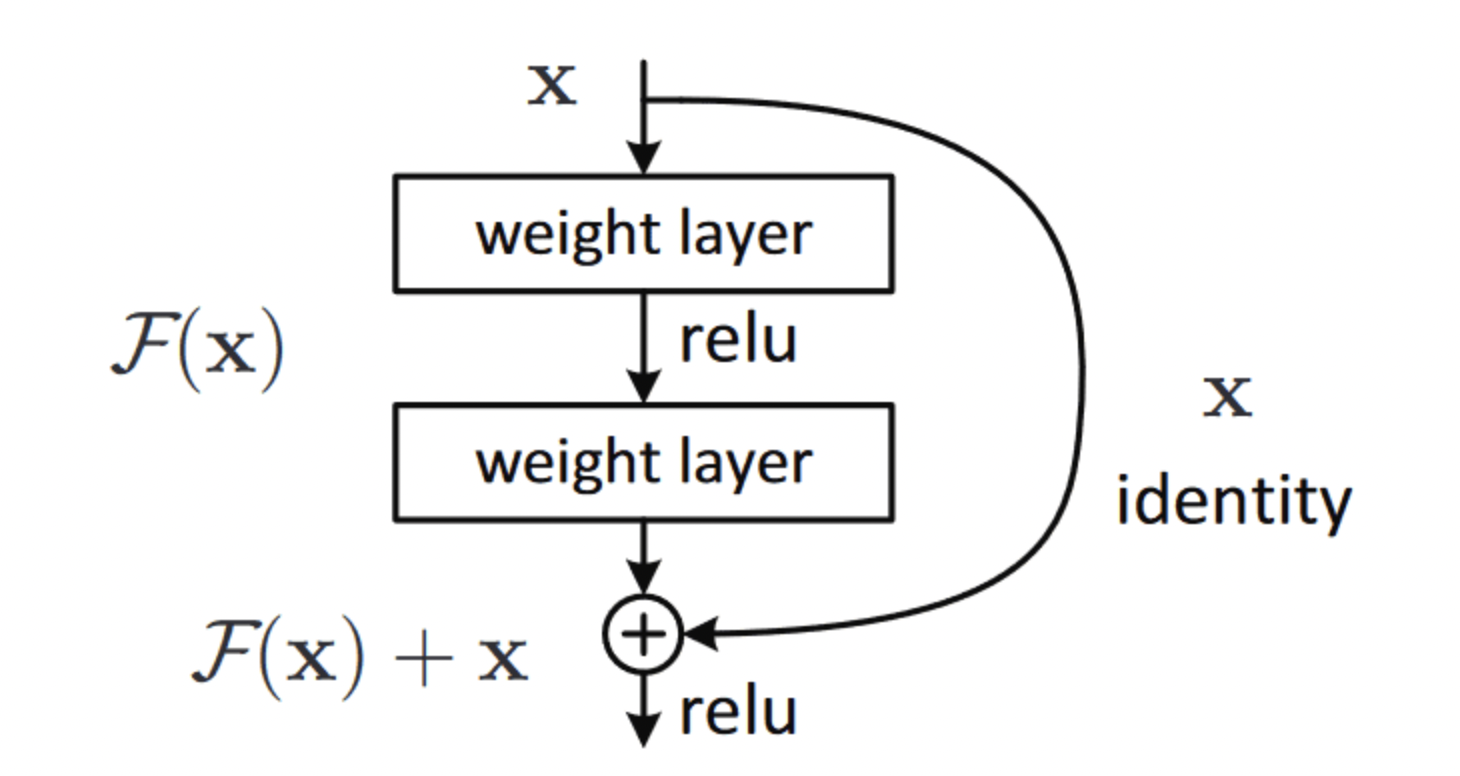 

In [62]:
# import packages
import tensorflow as tf
from tensorflow.keras.layers import BatchNormalization
from keras.layers.convolutional import Conv2D
from keras.layers.convolutional import MaxPooling2D
from keras.layers.convolutional import AveragePooling2D
from keras.layers.convolutional import ZeroPadding2D
from keras.layers.core import Activation
from keras.layers.core import Dense
from keras.layers import Flatten
from keras.layers import Input
from keras.layers import add
from keras.models import Model, load_model
from keras.regularizers import l2
from keras import backend as K
from sklearn.metrics import classification_report
from sklearn.preprocessing import LabelBinarizer
from keras.preprocessing.image import ImageDataGenerator
from keras.callbacks import LearningRateScheduler, ModelCheckpoint, EarlyStopping
from keras.optimizers import SGD
from keras.datasets import cifar10
import numpy as np
import argparse
import os
import matplotlib.pyplot as plt
import matplotlib
matplotlib.use('Agg')
%matplotlib inline


In [2]:
class ResNet:
    @staticmethod
    
    #Creating the residual block
    def residual_module(data, K, stride, chanDim, reduce = False,
        reg = 0.0001, bnEps = 2e-5, bnMom = 0.9):
        # the shortcut branch of the ResNet module should be
        # initialize as the input (identity) data
        shortcut = data

        # the first block of the ResNet module are the 1x1 CONVs
        bn1 = BatchNormalization(axis = chanDim, epsilon = bnEps, momentum = bnMom)(data)
        act1 = Activation("relu")(bn1)
        conv1 = Conv2D(int(K * 0.25), (1, 1), use_bias = False,
            kernel_regularizer = l2(reg))(act1)

        # the second block of the ResNet module are the 3x3 CONVs
        bn2 = BatchNormalization(axis = chanDim, epsilon = bnEps, momentum = bnMom)(conv1)
        act2 = Activation("relu")(bn2)
        conv2 = Conv2D(int(K * 0.25), (3, 3), strides = stride, padding = "same",
            use_bias = False, kernel_regularizer = l2(reg))(act2)

        # the third block of the ResNet module is another set of 1x1 CONVs
        bn3 = BatchNormalization(axis = chanDim, epsilon = bnEps, momentum = bnMom)(conv2)
        act3 = Activation("relu")(bn3)
        conv3 = Conv2D(K, (1, 1), use_bias = False, kernel_regularizer = l2(reg))(act3)

        # if we are to reduce the spatial size, apply a CONV layer to the shortcut
        if reduce:
            shortcut = Conv2D(K, (1, 1), strides = stride, use_bias = False,
                kernel_regularizer = l2(reg))(act1)

        # add together the shortcut and the final CONV
        x = add([conv3, shortcut])

        # return the addition as the output of the ResNet module
        return x

    @staticmethod
    def build(width, height, depth, classes, stages, filters, reg = 0.0001,
        bnEps = 2e-5, bnMom = 0.9, dataset = "cifar"):
        # initialize the input shape to be "channels last"
        # and the channels dimension itself
        inputShape = (height, width, depth)
        opt = SGD(learning_rate = INIT_LR, momentum = 0.9)
        chanDim = -1

        # set the input and apply BN
        inputs = Input(shape = inputShape)
        x = BatchNormalization(axis = chanDim, epsilon = bnEps, momentum = bnMom)(inputs)
        x = Conv2D(filters[0], (3, 3), use_bias = False, padding = "same", kernel_regularizer = l2(reg))(x)

        # loop over the number of stages
        for i in range(0, len(stages)):
            # initialize the stride, then apply a residual module
            # used to reduce the spatial size of the input volume
            stride = (1, 1) if i == 0 else (2, 2)
            x = ResNet.residual_module(x, filters[i + 1], stride, chanDim,
                reduce = True, bnEps = bnEps, bnMom = bnMom)

            # loop over the number of layers in the stage
            for j in range(0, stages[i] - 1):
                # apply a ResNet module
                x = ResNet.residual_module(x, filters[i + 1], (1, 1), chanDim,
                    bnEps = bnEps, bnMom = bnMom)

        # apply BN => ACT => POOL
        x = BatchNormalization(axis = chanDim, epsilon = bnEps, momentum = bnMom)(x)
        x = Activation("relu")(x)
        x = AveragePooling2D((8, 8))(x)

        # softmax classifier
        x = Flatten()(x)
        x = Dense(classes, kernel_regularizer = l2(reg))(x)
        x = Activation("softmax")(x)

        # create the model
        model = Model(inputs, x, name = "resnet")

        #Compiling model
        model.compile(loss = "categorical_crossentropy", optimizer = opt, metrics = ["accuracy"])

        # return the constructed network architecture
        return model

In [67]:
((trainX, trainY), (testX, testY)) = cifar10.load_data()
trainX = trainX.astype("float")
testX = testX.astype("float")

# apply mean subtraction to the data
trainX_mean = np.mean(trainX, axis=(0,1,2))
trainX_std = np.std(trainX, axis=(0,1,2))
trainX = (trainX - trainX_mean) / trainX_std #(input - mean)/standard deviation
testX = (testX - trainX_mean) / trainX_std

# convert the labels from integers to vectors
lb = LabelBinarizer()
trainY = lb.fit_transform(trainY)
testY = lb.transform(testY)

# construct the image generator for data augmentation
aug = ImageDataGenerator(width_shift_range = 0.1, height_shift_range = 0.1, horizontal_flip = True, fill_mode = "nearest")

In [4]:
def poly_decay(epoch):
    maxEpochs = NUM_EPOCHS
    baseLR = INIT_LR
    power = 1.0
    alpha = baseLR * (1 - (epoch / float(maxEpochs))) ** power
    return alpha

In [9]:
# define the total number of epochs to train for along with the initial learning rate
NUM_EPOCHS = 10
INIT_LR = 1e-1
callbacks = [LearningRateScheduler(poly_decay)]

In [ ]:
model = ResNet.build(32, 32, 3, 10, (9, 9, 9), (64, 64, 128, 256), reg = 0.0005)

In [ ]:
ResNet_history = model.fit(
    aug.flow(trainX, trainY, batch_size = 128),
    validation_data = (testX, testY),
    steps_per_epoch = len(trainX) // 128,
    epochs = NUM_EPOCHS,
    callbacks = callbacks,
    verbose = 1
)

Epoch 1/10
390/390 [==============================] - 81s 168ms/step - loss: 2.2188 - accuracy: 0.4104 - val_loss: 2.0229 - val_accuracy: 0.4778 - lr: 0.1000
Epoch 2/10
390/390 [==============================] - 65s 165ms/step - loss: 1.6498 - accuracy: 0.5998 - val_loss: 1.6310 - val_accuracy: 0.6018 - lr: 0.0900
Epoch 3/10
390/390 [==============================] - 63s 161ms/step - loss: 1.3570 - accuracy: 0.6893 - val_loss: 1.3487 - val_accuracy: 0.6968 - lr: 0.0800
Epoch 4/10
390/390 [==============================] - 63s 161ms/step - loss: 1.1718 - accuracy: 0.7463 - val_loss: 1.1839 - val_accuracy: 0.7290 - lr: 0.0700
Epoch 5/10
390/390 [==============================] - 63s 161ms/step - loss: 1.0504 - accuracy: 0.7784 - val_loss: 1.1783 - val_accuracy: 0.7479 - lr: 0.0600
Epoch 6/10
390/390 [==============================] - 63s 161ms/step - loss: 0.9579 - accuracy: 0.8037 - val_loss: 1.2042 - val_accuracy: 0.7447 - lr: 0.0500
Epoch 7/10
390/390 [==============================] 

In [ ]:
score=model.evaluate(testX, testY)
print('Test Score=',score[0])
print('Test Accuracy=',score[1])

313/313 [==============================] - 7s 21ms/step - loss: 0.7921 - accuracy: 0.8530
Test Score= 0.7921133637428284
Test Accuracy= 0.8529999852180481


In [ ]:
def fit_with(batch_size, reg):
  model = ResNet.build(32, 32, 3, 10, (9, 9, 9), (64, 64, 128, 256), reg = reg)
  model.fit(
    aug.flow(trainX, trainY, batch_size = round(batch_size)),
    validation_data = (testX, testY),
    steps_per_epoch = round(len(trainX) // batch_size),
    epochs = NUM_EPOCHS,
    callbacks = callbacks,
    verbose = 0)
  
  score=model.evaluate(testX, testY)
  print('Test Score=',score[0])
  print('Test Accuracy=',score[1])

  return score[1]

In [ ]:
from bayes_opt import BayesianOptimization

bounds = {
    'batch_size':(64, 256),
    'reg':(0.0001, 0.0005)
}
optimizer = BayesianOptimization(fit_with, bounds, random_state = 1, verbose = 2)
optimizer.maximize(init_points=4, n_iter=2)

for i, res in enumerate(optimizer.res):
  print("Iteration {}: \n\t{}".format(i, res))

|   iter    |  target   | batch_... |    reg    |
-------------------------------------------------
313/313 [==============================] - 6s 19ms/step - loss: 0.7540 - accuracy: 0.8634
Test Score= 0.7540014386177063
Test Accuracy= 0.8633999824523926
| 1         | 0.8634    | 144.1     | 0.0003881 |
313/313 [==============================] - 4s 14ms/step - loss: 0.6876 - accuracy: 0.8689
Test Score= 0.6876425743103027
Test Accuracy= 0.8689000010490417
| 2         | 0.8689    | 64.02     | 0.0002209 |
313/313 [==============================] - 5s 15ms/step - loss: 0.7483 - accuracy: 0.8605
Test Score= 0.7482798099517822
Test Accuracy= 0.8604999780654907
| 3         | 0.8605    | 92.18     | 0.0001369 |


313/313 [==============================] - 5s 15ms/step - loss: 2.0011 - accuracy: 0.5012
Test Score= 2.00114107131958
Test Accuracy= 0.5012000203132629
| 4         | 0.5012    | 99.76     | 0.0002382 |
313/313 [==============================] - 4s 14ms/step - loss: 0.6664 - accuracy: 0.8740
Test Score= 0.6664038300514221
Test Accuracy= 0.8740000128746033
| 5         | 0.874     | 64.29     | 0.0001717 |


313/313 [==============================] - 4s 14ms/step - loss: 1.8290 - accuracy: 0.5436
Test Score= 1.8290421962738037
Test Accuracy= 0.5436000227928162
| 6         | 0.5436    | 85.55     | 0.0003602 |
Iteration 0: 
	{'target': 0.8633999824523926, 'params': {'batch_size': 144.0682249028942, 'reg': 0.00038812979737686324}}
Iteration 1: 
	{'target': 0.8689000010490417, 'params': {'batch_size': 64.02195996493022, 'reg': 0.00022093302905273592}}
Iteration 2: 
	{'target': 0.8604999780654907, 'params': {'batch_size': 92.1771310368857, 'reg': 0.00013693543790751914}}
Iteration 3: 
	{'target': 0.5012000203132629, 'params': {'batch_size': 99.76196058451282, 'reg': 0.0002382242908172191}}
Iteration 4: 
	{'target': 0.8740000128746033, 'params': {'batch_size': 64.28885827560282, 'reg': 0.0001717438177751748}}
Iteration 5: 
	{'target': 0.5436000227928162, 'params': {'batch_size': 85.54935348020732, 'reg': 0.00036024075881903393}}


In [ ]:
print(optimizer.max)

{'target': 0.8740000128746033, 'params': {'batch_size': 64.28885827560282, 'reg': 0.0001717438177751748}}


In [5]:
checkpoint_path = "training_2/cp-{epoch:04d}.ckpt"
checkpoint_dir = os.path.dirname(checkpoint_path)

In [11]:
checkpoint = ModelCheckpoint(filepath=checkpoint_path,
                             monitor='accuracy',
                             verbose=1)

#Stop model from continuing when the accuracy does not increase after 25 continuous epochs. 
#The model will then restore model weights from the epoch with the best
early_stopping = EarlyStopping(monitor='val_accuracy', mode='max', verbose=0, patience=20, restore_best_weights = True)

In [7]:
import absl.logging
absl.logging.set_verbosity(absl.logging.ERROR)

In [30]:
callbacks=[checkpoint, early_stopping, LearningRateScheduler(poly_decay)]
batch_size = 64
reg = 0.0002
NUM_EPOCHS = 100

optimized_model = ResNet.build(32, 32, 3, 10, (9, 9, 9), (64, 64, 128, 256), reg = reg)
ResNet_history = optimized_model.fit(
    aug.flow(trainX, trainY, batch_size = batch_size),
    validation_data = (testX, testY),
    steps_per_epoch = len(trainX) // batch_size,
    epochs = NUM_EPOCHS,
    callbacks = callbacks,
    verbose = 1
)

Epoch 1/100
781/781 [==============================] - ETA: 0s - loss: 2.0736 - accuracy: 0.4303
Epoch 1: saving model to training_2/cp-0001.ckpt
781/781 [==============================] - 117s 137ms/step - loss: 2.0736 - accuracy: 0.4303 - val_loss: 2.2279 - val_accuracy: 0.4354 - lr: 0.1000
Epoch 2/100
781/781 [==============================] - ETA: 0s - loss: 1.5153 - accuracy: 0.6192
Epoch 2: saving model to training_2/cp-0002.ckpt
781/781 [==============================] - 104s 133ms/step - loss: 1.5153 - accuracy: 0.6192 - val_loss: 1.3891 - val_accuracy: 0.6546 - lr: 0.0990
Epoch 3/100
781/781 [==============================] - ETA: 0s - loss: 1.2485 - accuracy: 0.7045
Epoch 3: saving model to training_2/cp-0003.ckpt
781/781 [==============================] - 104s 133ms/step - loss: 1.2485 - accuracy: 0.7045 - val_loss: 1.2733 - val_accuracy: 0.6931 - lr: 0.0980
Epoch 4/100
781/781 [==============================] - ETA: 0s - loss: 1.1042 - accuracy: 0.7437
Epoch 4: saving model

In [31]:
optimized_model.save('resnet.h5')

In [32]:
optimized_modelv2 = load_model('resnet.h5')

In [34]:
NUM_EPOCHS = 20
INIT_LR = 1e-3
callbacks=[checkpoint, early_stopping, LearningRateScheduler(poly_decay)]

ResNet_historyv2 = optimized_modelv2.fit(
    aug.flow(trainX, trainY, batch_size = batch_size),
    validation_data = (testX, testY),
    steps_per_epoch = len(trainX) // batch_size,
    epochs = NUM_EPOCHS,
    callbacks = callbacks,
    verbose = 1
)

Epoch 1/20
781/781 [==============================] - ETA: 0s - loss: 0.1780 - accuracy: 0.9965
Epoch 1: saving model to training_2/cp-0001.ckpt
781/781 [==============================] - 106s 136ms/step - loss: 0.1780 - accuracy: 0.9965 - val_loss: 0.4094 - val_accuracy: 0.9356 - lr: 0.0010
Epoch 2/20
781/781 [==============================] - ETA: 0s - loss: 0.1776 - accuracy: 0.9966
Epoch 2: saving model to training_2/cp-0002.ckpt
781/781 [==============================] - 104s 133ms/step - loss: 0.1776 - accuracy: 0.9966 - val_loss: 0.4132 - val_accuracy: 0.9352 - lr: 9.5000e-04
Epoch 3/20
781/781 [==============================] - ETA: 0s - loss: 0.1766 - accuracy: 0.9969
Epoch 3: saving model to training_2/cp-0003.ckpt
781/781 [==============================] - 108s 138ms/step - loss: 0.1766 - accuracy: 0.9969 - val_loss: 0.4139 - val_accuracy: 0.9350 - lr: 9.0000e-04
Epoch 4/20
781/781 [==============================] - ETA: 0s - loss: 0.1749 - accuracy: 0.9975
Epoch 4: saving m

In [35]:
score=optimized_modelv2.evaluate(testX, testY)
print('Test Score=',score[0])
print('Test Accuracy=',score[1])

313/313 [==============================] - 4s 14ms/step - loss: 0.4083 - accuracy: 0.9372
Test Score= 0.4083089232444763
Test Accuracy= 0.9372000098228455


In [74]:
optimized_modelv2.save('finalresnet.h5')

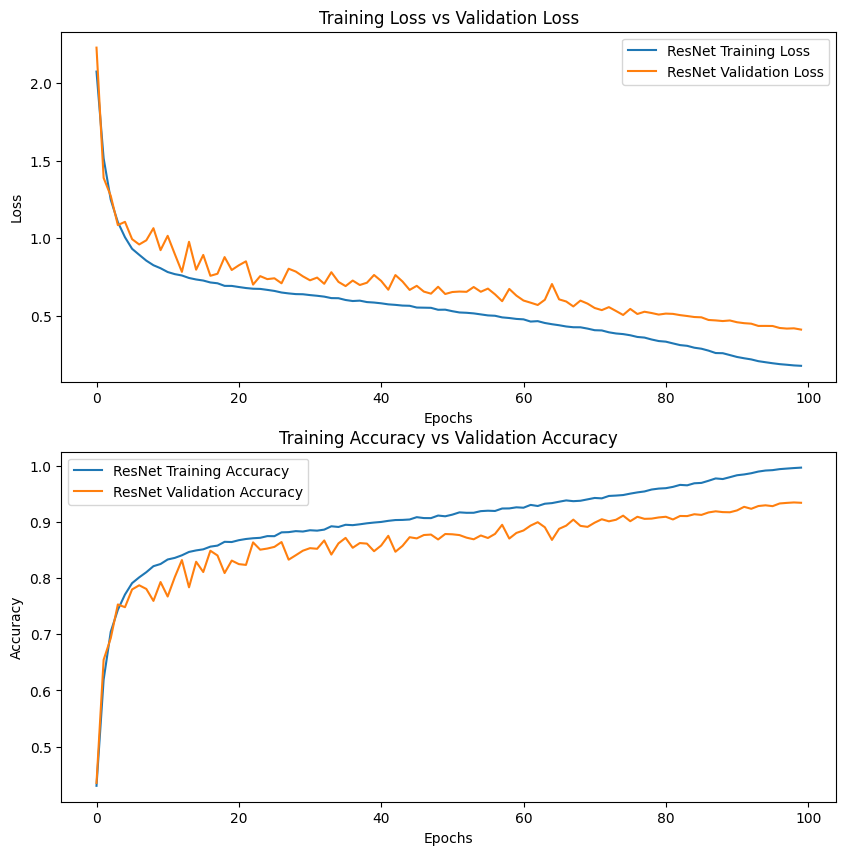

In [68]:
fig, axs = plt.subplots(2, 1, figsize=(10,10))

axs[0].plot(ResNet_history.history['loss'])
axs[0].plot(ResNet_history.history['val_loss'])

axs[0].title.set_text('Training Loss vs Validation Loss')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend(['ResNet Training Loss', 'ResNet Validation Loss'])

axs[1].plot(ResNet_history.history['accuracy'])
axs[1].plot(ResNet_history.history['val_accuracy'])
axs[1].title.set_text('Training Accuracy vs Validation Accuracy')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].legend(['ResNet Training Accuracy', 'ResNet Validation Accuracy'])

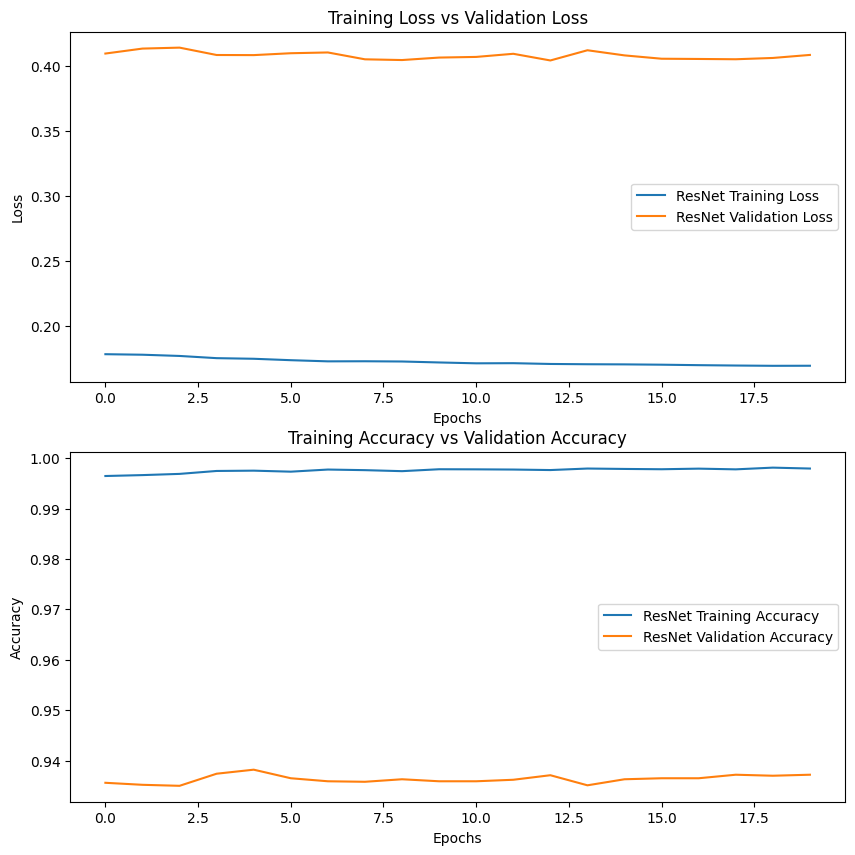

In [73]:
fig, axs = plt.subplots(2, 1, figsize=(10,10))

axs[0].plot(ResNet_historyv2.history['loss'])
axs[0].plot(ResNet_historyv2.history['val_loss'])

axs[0].title.set_text('Training Loss vs Validation Loss')
axs[0].set_xlabel('Epochs')
axs[0].set_ylabel('Loss')
axs[0].legend(['ResNet Training Loss', 'ResNet Validation Loss'])

axs[1].plot(ResNet_historyv2.history['accuracy'])
axs[1].plot(ResNet_historyv2.history['val_accuracy'])
axs[1].title.set_text('Training Accuracy vs Validation Accuracy')
axs[1].set_xlabel('Epochs')
axs[1].set_ylabel('Accuracy')
axs[1].legend(['ResNet Training Accuracy', 'ResNet Validation Accuracy'])

In [47]:
pred = optimized_modelv2.predict(testX)

313/313 [==============================] - 7s 15ms/step


In [48]:
from sklearn.metrics import classification_report
y_pred = np.argmax(pred, axis=1)
y_true = np.argmax(testY, axis=1)
print(classification_report(y_true, y_pred))

              precision    recall  f1-score   support

           0       0.94      0.96      0.95      1000
           1       0.97      0.97      0.97      1000
           2       0.92      0.92      0.92      1000
           3       0.87      0.85      0.86      1000
           4       0.93      0.95      0.94      1000
           5       0.90      0.89      0.89      1000
           6       0.94      0.96      0.95      1000
           7       0.98      0.94      0.96      1000
           8       0.98      0.95      0.96      1000
           9       0.95      0.97      0.96      1000

    accuracy                           0.94     10000
   macro avg       0.94      0.94      0.94     10000
weighted avg       0.94      0.94      0.94     10000



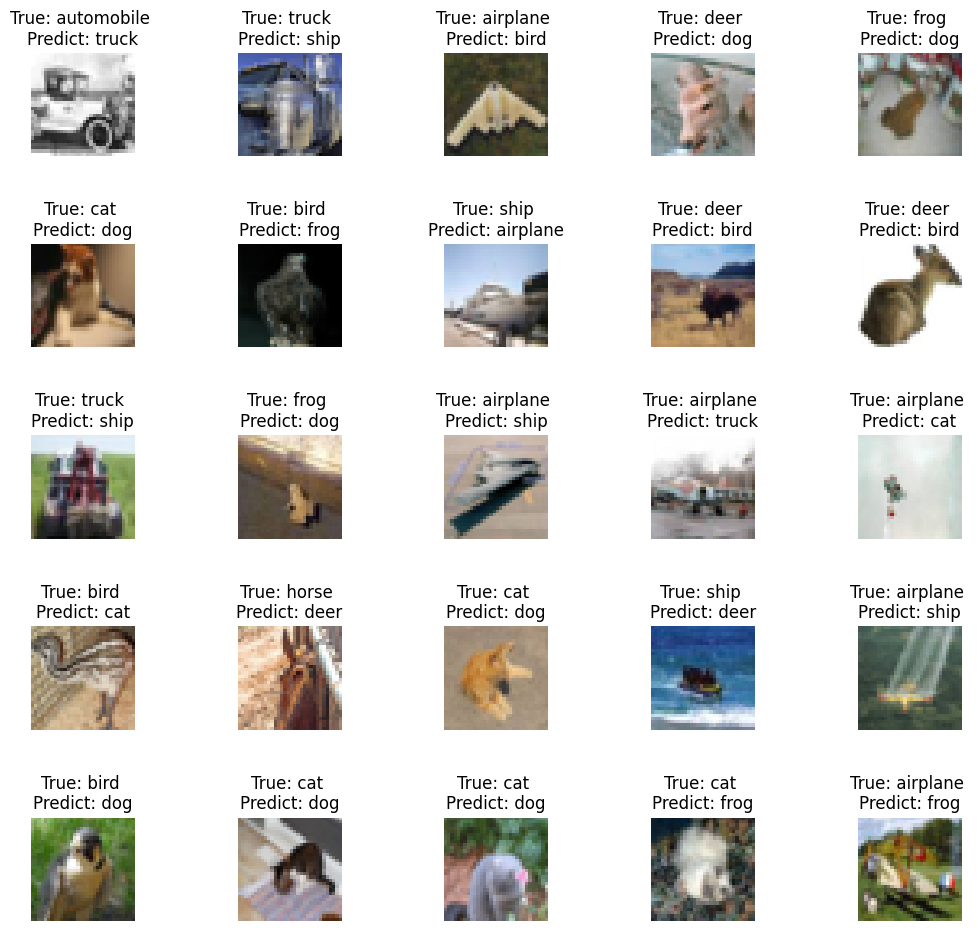

In [69]:
fig, axes = plt.subplots(5, 5, figsize=(12,12))
axes = axes.ravel()
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

trainX = (trainX * trainX_std) + trainX_mean
testX = (testX * trainX_std) + trainX_mean

miss_pred = np.where(y_pred != y_true)[0]
for i in np.arange(25): 
    axes[i].imshow(testX[miss_pred[i]].astype('uint8'))
    axes[i].set_title('True: %s \nPredict: %s' % (class_names[y_true[miss_pred[i]]], class_names[y_pred[miss_pred[i]]]))
    axes[i].axis('off')
    plt.subplots_adjust(wspace=1)

In [70]:
from sklearn.metrics import ConfusionMatrixDisplay
confusion_matrix = tf.math.confusion_matrix(labels=y_true, predictions=y_pred)
confusion_matrix = confusion_matrix.numpy()

Text(0.5, 1.0, 'Confusion Matrix')

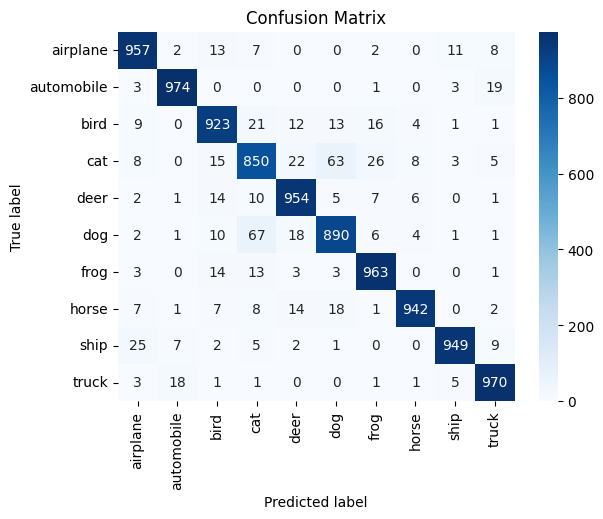

In [71]:
sns.heatmap(confusion_matrix, annot=True, fmt="g", xticklabels = class_names, yticklabels = class_names, cmap=plt.cm.Blues)
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.title('Confusion Matrix')

In [72]:
#Convert the model
converter = tf.lite.TFLiteConverter.from_keras_model(optimized_modelv2)
tflite_model = converter.convert()

#Save the model
with open('ResNet.tflite', 'wb') as f:
  f.write(tflite_model)